# 00. Prepare minimal tables from the raw data

This notebook is **not needed** to reproduce the figure panels: all tables it produces are already stored in `../data`.
It documents how those tables were derived from the full datasets (single-cell `.h5ad` objects, GeoMx and COPDGene files),
which are too large and/or access-restricted to be distributed with this repository.

Run it from the `code` directory with the original analysis project available in `../full` (its `data/` folder).

In [1]:
from pathlib import Path
import shutil

import h5py
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
from anndata import AnnData
from anndata.experimental import read_elem

RAW = Path("../full/data")  # Data folder of the original analysis project (full/, not distributed)
OUT = Path("../data")     # Minimal tables used by the figure notebooks
OUT.mkdir(exist_ok=True)

## Genes of the SIMs signature (used in Fig. 2a)

In [2]:
sim_markers = {
    "Positive": ["FNDC3B", "LRMDA", "ZFAND3", "AKAP13", "RBM47", "ZSWIM6", "DPYD", "LPP", "PLXDC2", "ZEB2", "RASGEF1B", "KYNU", "ASAP1", "ARHGAP26", "SIK3", "PRMT7", "ANO5"],
    "Negative": ["S100A4", "FTH1", "C1QB", "HLA-DRB1", "FTL", "CST3", "TYROBP", "HLA-DRA", "S100A11", "TMSB10", "S100A6", "C1QA", "CD74", "B2M", "TMSB4X", "IGFBP2", "GPD1"],
}
sim_genes = sim_markers["Positive"] + sim_markers["Negative"]


def read_csc_columns(group, gene_positions, n_rows):
    """Read selected columns of a CSC matrix stored in an h5ad file without loading the whole matrix."""
    indptr = group["indptr"][:]
    columns = []
    for position in gene_positions:
        start, end = indptr[position], indptr[position + 1]
        data = group["data"][start:end]
        rows = group["indices"][start:end]
        columns.append(sp.csc_matrix((data, rows, np.array([0, len(data)])), shape=(n_rows, 1)))
    return sp.hstack(columns).tocsr()

## Lung single-cell data

Source: `5_patient_representation_processed.h5ad` (175,694 cells). We extract
1. UMAP coordinates and cell type labels (Fig. 1c),
2. per-sample proportions of immune cell types (Fig. 2c),
3. log fold changes of the SIMs signature genes between macrophage subtypes (Fig. 2a).

In [3]:
with h5py.File(RAW / "5_patient_representation_processed.h5ad", "r") as h:
    lung_obs = read_elem(h["obs"])
    lung_umap = read_elem(h["obsm"]["X_umap_latent"])
    lung_scanvi = read_elem(h["obsm"]["X_scanvi"])
    lung_cell_type_colors = read_elem(h["uns"]["cell_type_reannotated_colors"])
    lung_raw_var = read_elem(h["raw"]["var"])
    gene_positions = [lung_raw_var.index.get_loc(gene) for gene in sim_genes]
    lung_raw_sim = read_csc_columns(h["raw"]["X"], gene_positions, n_rows=lung_obs.shape[0])

lung_obs["cell_type_reannotated"] = lung_obs["cell_type_reannotated"].cat.rename_categories(
    {"Macrophages_2": "Macrophages_Smoking-induced", "T_?": "T_senescence-associated"}
)
lung_obs.shape

(175694, 87)

In [4]:
# Fig. 1c: UMAP coordinates
lung_umap_df = pd.DataFrame(lung_umap, columns=["UMAP1", "UMAP2"], index=lung_obs.index)
lung_umap_df["cell_type"] = lung_obs["cell_type_reannotated"].values
lung_umap_df.to_csv(OUT / "lung_umap.csv")

pd.DataFrame({
    "cell_type": lung_obs["cell_type_reannotated"].cat.categories,
    "color": lung_cell_type_colors,
}).to_csv(OUT / "lung_cell_type_colors.csv", index=False)
lung_umap_df.shape

(175694, 3)

In [5]:
# Fig. 2c: proportions of immune cell types per sample (in %)
metadata = pd.read_csv(RAW / "6_metadata_clean.csv")

is_immune = lung_obs["lineage"] == "Immune"
immune_props = pd.crosstab(lung_obs.loc[is_immune, "sample_id"], lung_obs.loc[is_immune, "cell_type_reannotated"], normalize="index") * 100
immune_props.columns = immune_props.columns.astype(str)
immune_props = immune_props.loc[:, immune_props.sum() > 0]  # Drop non-immune categories
immune_props["n_cells"] = lung_obs["sample_id"].value_counts().loc[immune_props.index]  # All cells, not only immune
immune_props = immune_props.merge(metadata[["sample_id", "Smoking Status", "Emphysema Progression"]], left_index=True, right_on="sample_id").set_index("sample_id")
immune_props.to_csv(OUT / "3_lung_immune_cell_type_proportions.csv")
immune_props.shape

(78, 24)

In [6]:
# Fig. 2a (lung): log fold changes of SIMs signature genes between macrophage subtypes.
# As in the original analysis, the test is run on log1p-transformed normalised counts (adata.raw) with scanpy's default t-test.
# The log fold change of a gene depends only on that gene, so we only need to load the signature genes.
is_macrophage = lung_obs["cell_type_reannotated"].astype(str).str.contains("Macro").values
mac_lung = AnnData(
    X=lung_raw_sim[is_macrophage].copy(),
    obs=lung_obs.loc[is_macrophage, ["cell_type_reannotated"]].copy(),
    var=pd.DataFrame(index=sim_genes),
)
mac_lung.obs["cell_type_reannotated"] = mac_lung.obs["cell_type_reannotated"].cat.remove_unused_categories()
mac_lung.obsm["X_scanvi"] = lung_scanvi[is_macrophage]
sc.pp.log1p(mac_lung)
sc.tl.rank_genes_groups(mac_lung, groupby="cell_type_reannotated", method="t-test")

lung_logfc = (
    sc.get.rank_genes_groups_df(mac_lung, group=None)
    .pivot(index="group", columns="names", values="logfoldchanges")
    .loc[:, sim_genes]
)
lung_logfc.index.name = "cell_type"
lung_logfc.to_csv(OUT / "lung_macrophages_SIMs_signature_logFC.csv")

# Mean scANVI representation per macrophage subtype, used to build the dendrogram
lung_scanvi_mean = pd.DataFrame(mac_lung.obsm["X_scanvi"], index=mac_lung.obs_names).groupby(mac_lung.obs["cell_type_reannotated"].values).mean()
lung_scanvi_mean.index.name = "cell_type"
lung_scanvi_mean.to_csv(OUT / "lung_macrophages_scanvi_mean.csv")
lung_logfc.round(2)

/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/var/folders/tc/fk7_q9y91qq3phd1l5xxg7_h0000gn/T/ipykernel_83319/2746467998.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lung_scanvi_mean = pd.DataFrame(mac_lung.obsm["X_scanvi"], index=mac_lung.obs_names).groupby(mac_lung.obs["cell_type_reannotated"].values).mean()


names,FNDC3B,LRMDA,ZFAND3,AKAP13,RBM47,ZSWIM6,DPYD,LPP,PLXDC2,ZEB2,...,HLA-DRA,S100A11,TMSB10,S100A6,C1QA,CD74,B2M,TMSB4X,IGFBP2,GPD1
cell_type,,,,,,,,,,,,,,,,,,,,,
Macrophages_Smoking-induced,2.35,2.40,2.29,1.78,2.06,2.37,1.98,2.04,1.67,1.77,...,-3.11,-2.90,-3.06,-3.32,-3.55,-2.70,-2.89,-2.99,-2.22,-1.05
Macrophages_Alveolar,-1.19,-1.26,-1.09,-0.95,-1.13,-1.18,-1.16,-1.01,-0.83,-1.17,...,1.42,1.41,1.45,1.64,2.21,1.36,1.32,1.61,2.16,2.10
Macrophages_Alveolar_APOE,-0.93,-0.65,-1.00,-0.58,-0.52,-0.91,-0.36,-0.84,-0.68,-0.45,...,1.13,0.32,0.75,0.05,0.55,0.93,1.16,0.41,-2.08,-2.64
Macrophages_Interstitial,-0.53,-0.73,-0.70,-0.25,-0.40,-0.67,-0.32,-0.58,-0.27,0.26,...,0.61,0.94,0.76,1.19,-0.61,0.35,0.47,0.57,-1.65,-3.19
Macrophages_div,-0.14,-0.23,-0.61,-0.25,-0.63,-0.64,-0.53,-0.36,-0.33,-0.18,...,0.38,0.36,0.28,0.52,0.66,0.33,0.61,0.36,1.15,-1.63


## Blood single-cell data

Source: `20_blood_data_raw.h5ad` (93,171 cells, log-normalised expression). We extract
1. UMAP coordinates and cell type labels (Fig. 1d),
2. per-sample proportions of cell types (Fig. 2f),
3. log fold changes of the SIMs signature genes between monocyte subtypes (Fig. 2a).

In [7]:
with h5py.File(RAW / "20_blood_data_raw.h5ad", "r") as h:
    blood_obs = read_elem(h["obs"])
    blood_umap = read_elem(h["obsm"]["X_umap"])
    blood_pca = read_elem(h["obsm"]["X_pca"])
    blood_var = read_elem(h["var"])
    gene_positions = [blood_var.index.get_loc(gene) for gene in sim_genes]
    blood_X_sim = read_csc_columns(h["X"], gene_positions, n_rows=blood_obs.shape[0])

# PRMT7+ monocytes were defined as subclusters 17 and 23 of CD14 monocytes (see 16_blood_data_analysis.ipynb)
blood_obs["cell"] = blood_obs["cell"].astype(str)
blood_obs.loc[blood_obs["RNA_snn_res.1"].isin(["17", "23"]), "cell"] = "Monocytes_PRMT7+"
blood_obs["cell"].value_counts()

cell
CD4_TCM               20590
CD8_TEM               17962
CD4_Naive             12896
NK                     8237
Bnaive                 6021
CD14                   4584
B                      3614
Treg                   2724
ILC                    2554
Monocytes_PRMT7+       2314
CD8_Naive              2158
dnTorCD8               1793
NK_m                   1679
Platelet               1504
MAIT                    904
cDC                     810
gdT                     764
CD16                    735
NK_CD56bright           556
CD4_CTL                 343
pDC                     195
T/NK_proliferating      162
Plasmablast              72
Name: count, dtype: int64

/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


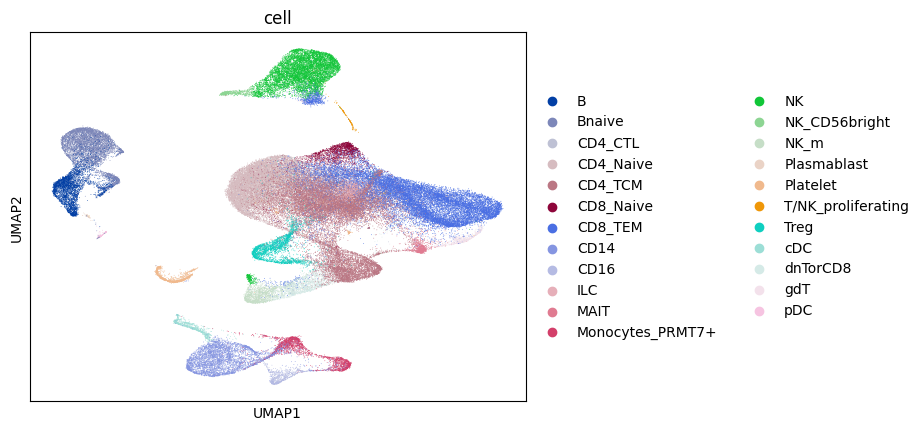

In [8]:
# Fig. 1d: UMAP coordinates
blood_umap_df = pd.DataFrame(blood_umap, columns=["UMAP1", "UMAP2"], index=blood_obs.index)
blood_umap_df["cell_type"] = blood_obs["cell"].values
blood_umap_df.to_csv(OUT / "blood_umap.csv")

# Colours: scanpy's default palette assigned when the UMAP was first plotted
blood_colors_adata = AnnData(obs=blood_obs[["cell"]].copy(), obsm={"X_umap": blood_umap})
sc.pl.umap(blood_colors_adata, color="cell", show=False)
pd.DataFrame({
    "cell_type": blood_colors_adata.obs["cell"].cat.categories,
    "color": blood_colors_adata.uns["cell_colors"],
}).to_csv(OUT / "blood_cell_type_colors.csv", index=False)

In [9]:
# Map blood samples (one per subject) to the clinical metadata
lobe_spec_to_subject_map = {
    'COPD10LLL': 'COPD10', 'COPD10LUL': 'COPD10', 'COPD2RUL': 'COPD2', 'COPD2LUL': 'COPD2', 'COPD4LLL': 'COPD4', 'COPD4RUL': 'COPD4',
    'COPD6LUL': 'COPD6', 'COPD6LLL': 'COPD6', 'COPD7LUL': 'COPD7', 'COPD7LLL': 'COPD7', 'COPD8LUL': 'COPD8', 'COPD8LLL': 'COPD8',
    'COPD1LUL': 'COPD1', 'COPD3RUL': 'COPD3', 'COPD5RLL': 'COPD5', 'UA100': 'UA100', 'UA102': 'UA102', 'UA104': 'UA104', 'UA16': 'UA16',
    'UA21': 'UA21', 'UA26': 'UA26', 'UA28': 'UA28', 'UA33': 'UA33', 'UA35': 'UA35', 'UA37': 'UA37', 'UA39': 'UA39', 'UA40': 'UA40',
    'UA42': 'UA42', 'UA44': 'UA44', 'UA45': 'UA45', 'UA48': 'UA48', 'UA50': 'UA50', 'UA53': 'UA53', 'UA56': 'UA56', 'UA58': 'UA58',
    'UA60': 'UA60', 'UA64': 'UA64', 'UA65': 'UA65', 'UA66': 'UA66', 'UA69': 'UA69', 'UA70': 'UA70', 'UA72': 'UA72', 'UA73': 'UA73',
    'UA74': 'UA74', 'UA78': 'UA78', 'UA90': 'UA90', 'UA94': 'UA94', 'UA96': 'UA96', 'DNAZ1LLL': 'DNAZ1', 'DNAZ1LUL': 'DNAZ1',
    'DNAZ2LUL': 'DNAZ2', 'DNAZ4RLL': 'DNAZ4', 'DNAZ4RML': 'DNAZ4', 'DNAZ4RUL': 'DNAZ4', 'DNAZ5LUL': 'DNAZ5', 'DNAZ6LLL': 'DNAZ6',
    'DNAZ6LUL': 'DNAZ6', 'DNAZ7RLL': 'DNAZ7', 'DNAZ7LLL': 'DNAZ7', 'UA27': 'UA27', 'UA30': 'UA30', 'UA32': 'UA32', 'UA36': 'UA36',
    'UA38': 'UA38', 'UA41': 'UA41', 'UA43': 'UA43', 'UA46': 'UA46', 'UA5': 'UA5', 'UA51': 'UA51', 'UA59': 'UA59', 'UA61': 'UA61', 'UA95': 'UA95',
}
blood_metadata = metadata.copy()
blood_metadata["orig.ident"] = blood_metadata["Subjet_Lobe_Specific"].map(lobe_spec_to_subject_map)
blood_metadata = blood_metadata.drop_duplicates(subset="orig.ident", keep="first")
blood_obs = blood_obs.merge(blood_metadata[["orig.ident", "sample_id", "Smoking Status", "Emphysema Progression"]], on="orig.ident", how="left")

# Fig. 2f: proportions of cell types per sample (in %)
cell_props = pd.crosstab(blood_obs["sample_id"], blood_obs["cell"], normalize="index") * 100
cell_props["n_cells"] = blood_obs["sample_id"].value_counts().loc[cell_props.index]
cell_props = cell_props.merge(blood_metadata[["sample_id", "Smoking Status", "Emphysema Progression"]], left_index=True, right_on="sample_id").set_index("sample_id")
cell_props.to_csv(OUT / "4_blood_cell_type_proportions.csv")
cell_props.shape

(52, 26)

In [10]:
# Fig. 2a (blood): log fold changes of SIMs signature genes between monocyte subtypes (scanpy's default t-test on log-normalised data)
is_monocyte = blood_obs["cell"].isin(["Monocytes_PRMT7+", "CD14", "CD16"]).values
monocytes = AnnData(
    X=blood_X_sim[is_monocyte].copy(),
    obs=blood_obs.loc[is_monocyte, ["cell"]].copy(),
    var=pd.DataFrame(index=sim_genes),
)
monocytes.obs["cell"] = monocytes.obs["cell"].astype("category")
monocytes.obsm["X_pca"] = blood_pca[is_monocyte]
sc.tl.rank_genes_groups(monocytes, groupby="cell", method="t-test")

blood_logfc = (
    sc.get.rank_genes_groups_df(monocytes, group=None)
    .pivot(index="group", columns="names", values="logfoldchanges")
    .loc[:, sim_genes]
)
blood_logfc.index.name = "cell_type"
blood_logfc.to_csv(OUT / "blood_monocytes_SIMs_signature_logFC.csv")

# Mean PCA representation per monocyte subtype, used to build the dendrogram
blood_pca_mean = pd.DataFrame(monocytes.obsm["X_pca"], index=monocytes.obs_names).groupby(monocytes.obs["cell"].values).mean()
blood_pca_mean.index.name = "cell_type"
blood_pca_mean.to_csv(OUT / "blood_monocytes_pca_mean.csv")
blood_logfc.round(2)

/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/var/folders/tc/fk7_q9y91qq3phd1l5xxg7_h0000gn/T/ipykernel_83319/92329961.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  blood_pca_mean = pd.DataFrame(monocytes.o

names,FNDC3B,LRMDA,ZFAND3,AKAP13,RBM47,ZSWIM6,DPYD,LPP,PLXDC2,ZEB2,...,HLA-DRA,S100A11,TMSB10,S100A6,C1QA,CD74,B2M,TMSB4X,IGFBP2,GPD1
cell_type,,,,,,,,,,,,,,,,,,,,,
CD14,-0.55,-1.04,-1.22,-0.85,-0.52,-1.22,-0.75,-1.51,-0.73,-1.35,...,2.28,2.86,3.68,4.03,-1.10,2.41,2.10,3.27,2.72,-18.52
CD16,-1.88,-2.01,-0.76,-0.48,-1.81,-1.16,-1.61,-0.46,-1.60,-0.57,...,1.11,1.84,1.17,1.35,3.71,0.88,1.84,1.75,-2.38,-17.34
Monocytes_PRMT7+,1.18,1.86,1.64,1.14,1.18,1.77,1.47,1.83,1.42,1.75,...,-3.46,-4.81,-4.96,-5.81,-2.90,-3.18,-3.25,-4.68,-2.49,18.92


## Pseudobulk differential expression results (lung and blood single-cell data)

These are the outputs of the mixed-model / edgeR analysis in `13_lung_data_analysis.ipynb` and `16_blood_data_analysis.ipynb`. Copied as they are.

In [11]:
shutil.copy(RAW / "13_lung_deg_results.csv", OUT / "6_lung_deg_results.csv")
shutil.copy(RAW / "14_blood_deg_results.csv", OUT / "7_blood_deg_results.csv")

PosixPath('../data/7_blood_deg_results.csv')

## GeoMx spatial transcriptomics

1. Differential expression results (fast vs slow progression per region) provided by the GeoMx analysis team, sheet "DE all". Used in Fig. 3c.
2. Cell type deconvolution results per region of interest. Used in Fig. 2b.

In [12]:
spatial_df = pd.read_excel(RAW / "From_Scott_282988_EmphysemaProgression_CombinedExpression_DEG.xlsx", sheet_name="DE all", skiprows=[1, 2])
spatial_df.to_csv(OUT / "8_GeoMx_DEG_results.csv", index=False)
spatial_df.shape

(7693, 78)

In [13]:
shutil.copy(RAW / "deconvolution_df.csv", OUT / "2_GeoMx_deconvolution_proportions.csv")

PosixPath('../data/2_GeoMx_deconvolution_proportions.csv')

## COPDGene bulk blood RNA-seq

1. Per-sample predicted fraction of PRMT7+ monocytes (InstaPrism deconvolution) with the covariates used in the mixed model (Fig. 2g) and the survival data (Fig. 2h).
   Sample filtering follows `31_analyse_bulk_data.ipynb`.
2. Differential expression results on the predicted cell type-specific expression (Fig. 3e, 3f).

Subject identifiers are not stored; COPDGene phenotype data are subject to a data use agreement.

In [14]:
bulk_master_metadata = pd.read_csv(RAW / "bulk_copd_gene/RNAseq/master.file.freeze5.phase2.csv", index_col=0)
bulk_metadata = pd.read_csv(RAW / "bulk_copd_gene/Phenotype/COPDGene_P1P2P3_SM_NS_Long_SEP24.txt", sep="\t", index_col=0, low_memory=False)
bulk_metadata = pd.merge(bulk_metadata, bulk_master_metadata, left_on="sid", right_on="actual_id")
bulk_metadata["emphysema"] = (bulk_metadata["pctEmph"] > 7.5).astype(int)
bulk_metadata.rename(columns={"Lc.Batch": "LcBatch"}, inplace=True)
bulk_metadata["smoking_status_former"] = (bulk_metadata["smoking_status"] == 1).astype(int)

# Emphysema progression: decrease of lung density between visits 2 and 3
bulk_metadata = bulk_metadata[bulk_metadata["final.analyzed"] == 1].copy()
bulk_metadata["visitnum"] = bulk_metadata["visitnum"].astype(str)
bulk_metadata["lung_density_vnb"] = pd.to_numeric(bulk_metadata["lung_density_vnb"])
bulk_metadata = bulk_metadata[bulk_metadata["visitnum"].isin(["2", "3"])]
bulk_metadata = bulk_metadata[bulk_metadata["lung_density_vnb"].notna()]

delta_dt = bulk_metadata.pivot_table(index="sample_id", columns="visitnum", values="lung_density_vnb")
delta_dt["delta_v23_LD"] = delta_dt["3"] - delta_dt["2"]
delta_dt["emphysema_progression"] = (delta_dt["delta_v23_LD"] <= -1.3).astype(int)
delta_dt = delta_dt.reset_index()[["sample_id", "delta_v23_LD", "emphysema_progression"]].dropna()

bulk_metadata = pd.merge(bulk_metadata, delta_dt, on="sample_id", how="left")
bulk_metadata.dropna(subset="delta_v23_LD", inplace=True)
bulk_metadata = bulk_metadata[bulk_metadata["visitnum"] == "2"]  # Keep the 2nd visit to predict value in a future timepoint

# Filter out scanners and batches with too few observations
scanner_counts = bulk_metadata["scanner_model_clean"].value_counts()
batch_counts = bulk_metadata["LcBatch"].value_counts()
bulk_metadata = bulk_metadata[
    bulk_metadata["scanner_model_clean"].isin(scanner_counts[scanner_counts > 10].index)
    & bulk_metadata["LcBatch"].isin(batch_counts[batch_counts > 10].index)
]
bulk_metadata.shape

(1898, 1060)

In [15]:
deconvolution_results = pd.read_csv(RAW / "bulk_copd_gene_results/instaPrism_deconvolution.csv", index_col=0)
deconvolution_results = deconvolution_results.loc[deconvolution_results["Platelet"] < 0.3]  # Outlier samples with too many platelets
deconvolution_results = bulk_metadata.merge(deconvolution_results, left_on="actual_id", right_index=True, how="inner")
deconvolution_results.dropna(subset=["emphysema_progression"], inplace=True)

# NaNs are encoded as 3 in the data
for col in ["Asthma", "HayFev", "ChronBronch"]:
    deconvolution_results.loc[deconvolution_results[col] == 3, col] = np.nan

deconvolution_results = deconvolution_results[deconvolution_results["Asthma"] == 0]
deconvolution_results = deconvolution_results[deconvolution_results["HayFev"] == 0]
deconvolution_results = deconvolution_results[deconvolution_results["CancerLung"] != 1]  # Missing is fine, likely not cancer
deconvolution_results.shape

(999, 1076)

In [16]:
mortality_df = pd.concat(
    [pd.read_csv(RAW / "bulk_copd_gene/Phenotype/Mortality/COPDGene_VitalStatus_SM_NS_Sep23.csv"),
     pd.read_csv(RAW / "bulk_copd_gene/Phenotype/Mortality/COPDGene_VitalStatus_ILDBR_Sep23.csv")],
    axis=0,
)
mortality_df = mortality_df.merge(deconvolution_results, left_on="sid", right_on="actual_id", how="inner")
mortality_df["days_followed_since_phase_2"] = mortality_df["days_followed"] - mortality_df["days_since_baseline"]

bulk_table = mortality_df[[
    "Monocytes_PRMT7+", "emphysema_progression", "lung_density_vnb", "pctEmph", "gender", "smoking_status", "age_visit", "LcBatch",
    "vital_status", "days_followed_since_phase_2",
]].copy()
bulk_table["LcBatch"] = bulk_table["LcBatch"].astype("category").cat.codes  # Anonymise batch labels
bulk_table = bulk_table.reset_index(drop=True)
bulk_table.index.name = "sample"
bulk_table.to_csv(OUT / "5_bulk_COPDGene_PRMT7_monocytes.csv")
bulk_table.shape

(999, 10)

In [17]:
for cell_type in ["Monocytes_Classical", "T_CD4", "T_reg", "Monocytes_PRMT7+"]:
    file_name = f"{cell_type}_Design2_emphysema_progression.csv"
    shutil.copy(RAW / "bulk_copd_gene_results/dge_results" / file_name, OUT / "9_bulk_dge_results" / file_name)

## Marker genes for the cell type annotation (supplementary dot plots)

For each cell type we store the mean expression and the fraction of expressing cells of the annotation marker genes.
Lung: log1p of the normalised counts (`adata.raw`), as plotted with `sc.pl.dotplot(..., log=True)`. Blood: log-normalised expression (`adata.X`).

In [18]:
lung_annotation_markers = [
    "AGER", "SFTPC", "SFTPA1", "SFTPD", "ERBB4", "KRT5", "SNTN", "SCGB1A1", "SCGB3A2", "SFTPB", "PRX", "CA4", "FCN3", "CX3CL1", "LUM", "ACTA2",
    "COX4I2", "GUCY1A2", "MCAM", "GUCY1B1", "PDGFRB", "EGFL6", "MARCO", "MSR1", "APOE", "MMP9", "PLA2G7", "CD163", "CD14", "SERPINB2", "FABP4",
    "CDKN1C", "FCGR3A", "GZMB", "KIR2DL4", "CD3E", "CD4", "CD8A", "FOXP3", "IL17A", "CDKN2A", "THEMIS", "CTLA4", "CD19", "CR2", "MS4A1", "JCHAIN",
    "IGHG1", "IL3RA", "HDC", "MS4A2",
]
blood_annotation_markers = [
    "MS4A1", "CD79A", "IGHD", "TCL1A", "CD27", "MZB1", "JCHAIN", "TNFRSF17", "CD3E", "CD2", "CCR7", "SELL", "LEF1", "TCF7", "CD4", "CD40LG",
    "CD8A", "CD8B", "IL7R", "LTB", "AQP3", "FOXP3", "IL2RA", "RTKN2", "IKZF2", "GZMA", "GZMH", "FGFBP2", "CCL5", "KLRB1", "SLC4A10", "TRDC",
    "TRGV9", "TRDV2", "TNFRSF4", "TNFRSF18", "NKG7", "GNLY", "KLRF1", "KLRD1", "NCAM1", "XCL1", "KLRC1", "MKI67", "STMN1", "TOP2A",
    "LYZ", "CD14", "S100A8", "S100A12", "VCAN", "LRMDA", "PLXDC2", "ZEB2", "NEAT1", "FCGR3A", "LST1", "CDKN1C", "MS4A7", "CD1C", "FCER1A",
    "CLEC10A", "IL3RA", "LILRA4", "CLEC4C", "IRF7", "PPBP", "PF4", "GP9",
]


def dotplot_tables(X, genes, groups):
    """Mean expression and fraction of expressing cells per group."""
    expression = pd.DataFrame(X.toarray(), columns=genes)
    mean = expression.groupby(groups.values).mean()
    fraction = (expression > 0).groupby(groups.values).mean()
    mean.index.name = fraction.index.name = "cell_type"
    return mean, fraction


with h5py.File(RAW / "5_patient_representation_processed.h5ad", "r") as h:
    gene_positions = [lung_raw_var.index.get_loc(gene) for gene in lung_annotation_markers]
    lung_raw_markers = read_csc_columns(h["raw"]["X"], gene_positions, n_rows=lung_obs.shape[0])
lung_raw_markers.data = np.log1p(lung_raw_markers.data)
mean, fraction = dotplot_tables(lung_raw_markers, lung_annotation_markers, lung_obs["cell_type_reannotated"].astype(str))
mean.to_csv(OUT / "18_lung_annotation_markers_mean_expression.csv")
fraction.to_csv(OUT / "19_lung_annotation_markers_fraction_expressing.csv")

with h5py.File(RAW / "20_blood_data_raw.h5ad", "r") as h:
    gene_positions = [blood_var.index.get_loc(gene) for gene in blood_annotation_markers]
    blood_X_markers = read_csc_columns(h["X"], gene_positions, n_rows=blood_obs.shape[0])
mean, fraction = dotplot_tables(blood_X_markers, blood_annotation_markers, blood_obs["cell"])
mean.to_csv(OUT / "20_blood_annotation_markers_mean_expression.csv")
fraction.to_csv(OUT / "21_blood_annotation_markers_fraction_expressing.csv")
mean.round(2)

,MS4A1,CD79A,IGHD,TCL1A,CD27,MZB1,JCHAIN,TNFRSF17,CD3E,CD2,...,CD1C,FCER1A,CLEC10A,IL3RA,LILRA4,CLEC4C,IRF7,PPBP,PF4,GP9
cell_type,,,,,,,,,,,,,,,,,,,,,
B,2.51,2.60,0.35,0.39,0.66,0.32,0.59,0.07,0.05,0.01,...,0.28,0.00,0.00,0.04,0.11,0.02,0.31,0.05,0.01,0.00
Bnaive,2.56,2.64,1.46,2.12,0.04,0.36,0.28,0.08,0.06,0.02,...,0.12,0.00,0.00,0.07,0.01,0.02,0.27,0.06,0.02,0.01
CD14,0.01,0.01,0.00,0.00,0.01,0.00,0.00,0.00,0.04,0.02,...,0.05,0.03,0.14,0.10,0.01,0.00,0.35,0.20,0.08,0.03
CD16,0.01,0.02,0.00,0.01,0.01,0.00,0.00,0.00,0.03,0.02,...,0.00,0.00,0.02,0.40,0.01,0.00,0.47,0.19,0.07,0.03
CD4_CTL,0.03,0.01,0.00,0.00,0.01,0.02,0.00,0.00,2.40,1.34,...,0.00,0.00,0.00,0.00,0.00,0.00,0.14,0.06,0.01,0.00
CD4_Naive,0.00,0.02,0.00,0.00,1.00,0.00,0.00,0.00,2.25,0.64,...,0.00,0.00,0.00,0.03,0.00,0.00,0.18,0.04,0.01,0.00
CD4_TCM,0.02,0.01,0.00,0.00,0.61,0.00,0.00,0.00,1.71,0.88,...,0.00,0.00,0.00,0.03,0.00,0.00,0.17,0.05,0.01,0.00
CD8_Naive,0.01,0.19,0.01,0.00,1.16,0.00,0.01,0.00,2.28,0.61,...,0.00,0.00,0.00,0.04,0.00,0.00,0.16,0.03,0.01,0.00
CD8_TEM,0.06,0.01,0.00,0.00,0.38,0.01,0.00,0.00,2.20,1.17,...,0.00,0.00,0.00,0.01,0.00,0.00,0.18,0.05,0.02,0.00


## Marker genes of lung macrophage subtypes (supplementary dot plots)

Mean log1p-normalised expression and fraction of expressing cells of macrophage and inflammation marker genes in the five macrophage subtypes.

In [19]:
lung_macrophage_markers = [
    # Macrophage subtype markers
    "LYZ", "MRC1", "APOE", "FBP1", "FCGR1A", "ITGAX", "ITGAM",
    "CD14", "IL1B", "FMN1", "TLR2", "GPR183", "DOCK4", "NLRP3", "NR4A2", "HIF1A",
    "PPARG", "ITGB8", "MSR1", "LSAMP", "TANC2", "LRMDA", "JMJD1C", "LPP", "HK1", "HK2", "ACSL1",
    "MKI67", "TOP2A", "PCNA", "BIRC5", "STMN1", "TUBB", "HMGN2", "UBE2C",
    "HLA-DQB2", "HLA-DQB1", "HLA-DQA1", "HLA-DRB5", "HLA-DRB1", "APOC1", "CD52", "LGALS3", "C1QA", "C1QB", "C1QC",
    # Inflammation markers
    "TNF", "IL6", "CXCL8", "CCL2", "CCL3", "CCL4",
    "IL10", "TGFB1", "IL1RN", "IL4", "IL13", "CCL18", "CCL22",
]

with h5py.File(RAW / "5_patient_representation_processed.h5ad", "r") as h:
    gene_positions = [lung_raw_var.index.get_loc(gene) for gene in lung_macrophage_markers]
    lung_raw_mac_markers = read_csc_columns(h["raw"]["X"], gene_positions, n_rows=lung_obs.shape[0])
lung_raw_mac_markers.data = np.log1p(lung_raw_mac_markers.data)
mean, fraction = dotplot_tables(lung_raw_mac_markers[is_macrophage], lung_macrophage_markers, lung_obs.loc[is_macrophage, "cell_type_reannotated"].astype(str))
mean.to_csv(OUT / "23_lung_macrophage_markers_mean_expression.csv")
fraction.to_csv(OUT / "24_lung_macrophage_markers_fraction_expressing.csv")
mean.round(2)

,LYZ,MRC1,APOE,FBP1,FCGR1A,ITGAX,ITGAM,CD14,IL1B,FMN1,...,CCL2,CCL3,CCL4,IL10,TGFB1,IL1RN,IL4,IL13,CCL18,CCL22
cell_type,,,,,,,,,,,,,,,,,,,,,
Macrophages_Alveolar,2.75,2.01,2.60,2.32,0.35,0.55,0.29,0.48,0.92,0.27,...,0.01,0.38,0.67,0.01,0.85,0.35,0.0,0.0,1.86,0.01
Macrophages_Alveolar_APOE,3.22,1.63,4.06,1.81,0.48,0.88,0.48,1.10,0.72,0.91,...,0.22,1.04,0.91,0.11,0.91,0.35,0.0,0.0,2.69,0.02
Macrophages_Interstitial,2.64,2.17,2.04,2.11,0.25,0.84,0.75,1.20,1.35,0.72,...,0.36,0.93,0.89,0.06,0.98,0.46,0.0,0.0,1.09,0.01
Macrophages_Smoking-induced,1.00,1.57,1.14,1.13,0.09,1.00,0.23,0.18,1.39,0.99,...,0.06,0.41,0.57,0.03,0.65,0.43,0.0,0.0,1.00,0.02
Macrophages_div,3.04,1.44,2.59,1.98,0.27,0.22,0.31,0.70,1.06,0.38,...,0.06,0.61,0.85,0.01,0.66,0.34,0.0,0.0,2.55,0.02


## Number of cells per cell type and sample (supplementary heatmap of sample contributions)

In [20]:
lung_cell_counts = pd.crosstab(lung_obs["cell_type_reannotated"].astype(str), lung_obs["sample_id"])
lung_cell_counts.index.name = "cell_type"
lung_cell_counts.to_csv(OUT / "22_lung_cell_counts_per_sample.csv")
lung_cell_counts.shape

(43, 78)

In [21]:
sorted(p.name for p in OUT.rglob("*") if p.is_file())

['.DS_Store',
 '10_ccc_mofa_factor_progression_tests.csv',
 '11_ccc_samples.csv',
 '12_ccc_mofa_progression_factor_r2_per_view.csv',
 '13_ccc_sim_receptor_summary.csv',
 '14_ccc_exemplar_interaction_tests.csv',
 '15_ccc_exemplar_interaction_scores.csv',
 '16_ccc_sim_pseudobulk_log_cpm.csv',
 '17_ccc_sim_edger_focus_receptors.csv',
 '18_lung_annotation_markers_mean_expression.csv',
 '19_lung_annotation_markers_fraction_expressing.csv',
 '20_blood_annotation_markers_mean_expression.csv',
 '21_blood_annotation_markers_fraction_expressing.csv',
 '22_lung_cell_counts_per_sample.csv',
 '23_lung_macrophage_markers_mean_expression.csv',
 '24_lung_macrophage_markers_fraction_expressing.csv',
 '2_GeoMx_deconvolution_proportions.csv',
 '3_lung_immune_cell_type_proportions.csv',
 '4_blood_cell_type_proportions.csv',
 '5_bulk_COPDGene_PRMT7_monocytes.csv',
 '6_lung_deg_results.csv',
 '7_blood_deg_results.csv',
 '8_GeoMx_DEG_results.csv',
 'Monocytes_Classical_Design2_emphysema_progression.csv',
 'M